# 33 Checks on the E_peaks: the time limit, GRB 160625B, the GBM catalogue, and the precursors that are only bounded

Every number about softness in notebooks 25, 26 and 29 is a ratio of E_peaks. So before they go in the report, I wanted to check four
things.

1. The time limit. To measure 220 bursts in days, the batch (`zhu.run`) gave each slow step of a fit 5 minutes, and Zhu et al.'s error
   search 10. A fit that runs out keeps its best start so far and says so, but its E_peak may not be the best fit, and its error may be
   missing. Section 1 refits every window where that could change an E_peak the notebooks use, with 30 minutes for each step (the default
   of `python -m grbtool`), and looks at what moves.
2. GRB 160625B, the one burst in Coppin et al.'s sample whose precursor came out as soft against its main emission as a merger's
   (notebook 29). Two papers have measured it, Zhang et al. (2018, Nature Astronomy 2, 69) and Ravasio et al. (2018, A&A 613, A16), and
   the GBM catalogue has its own fits. Section 2 puts ours next to all of them, window by window where they give windows.
3. The GBM catalogue's own fit of every burst's brightest second, repeated with our set-up, to check the data handling across both
   samples (section 3).
4. The confirmed bursts. Notebook 26 compares the confirmed mergers' precursors with the supernova collapsars' only where both E_peaks
   are measured. Section 4 adds the precursors whose E_peak is only bounded.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter
import pandas as pd

from coppin import RESULTS as COPPIN
from zhu import RESULTS as ZHU
from zhu import refit as R
from zhu.catalogue import EPI_LINE
from grbtool.bursts import DATA_ROOT
from zhu.features import collect, epi_summary

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
SOFT = 0.1876            # GRB 230307A's precursor E_peak over its main emission's (notebook 29)

## 1 The time limit

`zhu.refit.late_windows` reads every precursor (PE) and main-emission (ME) window of the zhu2026 and project modes, in both samples. It
keeps the ones where something that ran out could change the E_peak that's used. That can happen in four ways: the chosen model itself
ran out (A), its error search ran out (B), a model that ran out was close enough to the threshold that would have chosen it (C), or
something in Zhu et al.'s way ran out (Z). A model that ran out far from its threshold can't change the choice, so those aren't
refitted.

In [2]:
late = R.late_windows()
print(f"{len(late)} windows in {late.groupby(['sample', 'burst']).ngroups} bursts")
print(late.groupby(["sample", "why"]).size().unstack(fill_value=0).to_string())

81 windows in 60 bursts
why      A   B   C   Z
sample                
coppin  10  12   4  13
zhu     15   8  14   5


In [3]:
done = pd.read_csv(R.OUT / "refits.csv") if (R.OUT / "refits.csv").exists() else pd.DataFrame()
fitted = pd.Series(False, index=done.index)
for column in ("new_seconds", "new_zhu_seconds"):
    if column in done:
        fitted |= done[column].notna()
ran = done[fitted]
for column in ("new_Epeak", "new_zhu_Epeak", "new_model", "new_zhu_model", "new_ran_out", "new_zhu_flags", "new_Epeak_err_lo",
               "new_Epeak_err_hi", "new_zhu_Epeak_err_lo", "new_zhu_Epeak_err_hi", "new_measured"):
    if column not in ran:
        ran = ran.assign(**{column: np.nan})
print(f"refitted so far: {len(ran)} of {len(late)} windows" + ("" if len(ran) == len(late) else "  (python -m zhu.refit late --run)"))
if len(ran):
    ours = ran[ran.ours & ran.new_Epeak.notna()].copy()
    ours["change"] = ours.new_Epeak / ours.old_Epeak
    ours["model_changed"] = ours.new_model != ours.old_model
    ours["still_late"] = ours.new_ran_out.fillna("").astype(str).str.strip() != ""
    ours["errors_now"] = ours.new_Epeak_err_lo.notna() & ours.new_Epeak_err_hi.notna()
    theirs = ran[ran.zhu & ran.new_zhu_Epeak.notna()].copy()
    theirs["change"] = theirs.new_zhu_Epeak / theirs.old_zhu_Epeak
    theirs["model_changed"] = theirs.new_zhu_model != theirs.old_zhu_model
    theirs["still_late"] = theirs.new_zhu_flags.fillna("").astype(str).str.contains("out_of_time")
    for label, t in (("our rule", ours), ("their way", theirs)):
        dex = np.log10(t.change).abs()
        print(f"{label}: {len(t)} refitted; E_peak moved by a median {100 * (10 ** dex.median() - 1):.1f}%, by less than 1% in "
              f"{int((dex < np.log10(1.01)).sum())}, by more than 10% in {int((dex > np.log10(1.1)).sum())}; model changed in "
              f"{int(t.model_changed.sum())}; still out of time in {int(t.still_late.sum())}")
    print("our rule, errors found where they had run out:", int((ours.errors_now & ours.old_ran_out.fillna("").str.contains("errors")).sum()),
          "of", int(ours.old_ran_out.fillna("").str.contains("errors").sum()))
    cols = ["sample", "burst", "label", "modes", "why", "old_model", "new_model", "old_Epeak", "new_Epeak", "change"]
    big = ours[np.log10(ours.change).abs() > np.log10(1.1)].copy()
    print(big[cols].round(3).to_string(index=False))

    def batch_fit(r):
        """The batch's row for this window, from the mode whose E_peak the refit table took."""
        for mode in r.modes.split():
            b = pd.read_csv(R.SAMPLES[r["sample"]][0] / r.burst / f"spectra_{mode}.csv").set_index("label").loc[r.label]
            if np.isclose(b.Epeak, r.old_Epeak):
                return b
    batch = [batch_fit(r) for _, r in big.iterrows()]
    print("the two-break fits behind them (C_band - C_lowbreak; the change in the two-break's C; the batch's break energy):")
    print(pd.DataFrame({"burst": big.burst, "modes": big.modes, "dC_batch": [b.C_band - b.C_lowbreak for b in batch],
                        "dC_refit": big.new_C_band - big.new_C_lowbreak, "C_lowbreak_change": big.new_C_lowbreak - [b.C_lowbreak for b in batch],
                        "Eb_batch": [b.Eb for b in batch], "Epeak_lowbreak_batch": [b.Epeak_lowbreak for b in batch],
                        "Epeak_lowbreak_refit": big.new_Epeak_lowbreak, "flags_batch": [b.fit_flags for b in batch],
                        "flags_refit": big.new_fit_flags.fillna("")}).round(2).to_string(index=False))
    cols = ["sample", "burst", "label", "modes", "old_zhu_model", "new_zhu_model", "old_zhu_Epeak", "new_zhu_Epeak", "change"]
    print(theirs[np.log10(theirs.change).abs() > np.log10(1.1)][cols].round(3).to_string(index=False))

refitted so far: 81 of 81 windows
our rule: 63 refitted; E_peak moved by a median 0.0%, by less than 1% in 56, by more than 10% in 4; model changed in 3; still out of time in 3
their way: 25 refitted; E_peak moved by a median 0.0%, by less than 1% in 18, by more than 10% in 5; model changed in 6; still out of time in 3
our rule, errors found where they had run out: 27 of 28
sample   burst label           modes why    old_model    new_model  old_Epeak  new_Epeak  change
   zhu 090131A    ME project zhu2026   B         Band BandLowBreak     43.295     35.059   0.810
   zhu 150228B    ME         zhu2026   B         Band BandLowBreak     35.687     40.733   1.141
coppin 181119A    ME         zhu2026   A BandLowBreak BandLowBreak     54.529     41.917   0.769
coppin 181119A    ME         project   A BandLowBreak         Band     53.994     62.179   1.152
the two-break fits behind them (C_band - C_lowbreak; the change in the two-break's C; the batch's break energy):
  burst           modes  

What the refits do to the numbers the notebooks quote. There are three kinds: the E_peak ratios (our rule, with both E_peaks measured,
as notebooks 26 and 29 take them), the soft precursors (a ratio at or below GRB 230307A's), and EPI (Zhu et al.'s way, with a
main-emission E_peak from a model whose parameters are all constrained, as in notebook 29). Each is worked out with the batch's E_peaks
and again with the refitted ones in their place.

In [4]:
def with_refits(features, sample):
    """The zhu2026 features with the refitted E_peaks (and errors, models, flags) in place of the batch's."""
    f = features.copy()
    for label in ("PE", "ME"):
        f[f"measured_{label}"] = f[f"measured_{label}"].astype(str)
    if not len(ran):
        return f
    for _, r in ran[(ran["sample"] == sample) & ran.modes.str.contains("zhu2026")].iterrows():
        if r.burst not in f.index:
            continue
        if r.ours and pd.notna(r.get("new_Epeak")):
            f.loc[r.burst, [f"Ep_{r.label}_ours", f"Ep_{r.label}_ours_lo", f"Ep_{r.label}_ours_hi"]] = [r.new_Epeak, r.new_Epeak_err_lo, r.new_Epeak_err_hi]
            f.loc[r.burst, f"measured_{r.label}"] = str(r.new_measured)
        if r.zhu and pd.notna(r.get("new_zhu_Epeak")):
            f.loc[r.burst, [f"Ep_{r.label}_zhu", f"Ep_{r.label}_zhu_lo", f"Ep_{r.label}_zhu_hi"]] = [r.new_zhu_Epeak, r.new_zhu_Epeak_err_lo, r.new_zhu_Epeak_err_hi]
            f.loc[r.burst, f"zhu_flags_{r.label}"] = r.new_zhu_flags
            f.loc[r.burst, f"model_{r.label}_zhu"] = r.new_zhu_model
    return f


def ratios(f):
    both = (f.measured_PE.astype(str) == "True") & (f.measured_ME.astype(str) == "True")
    return (f.Ep_PE_ours / f.Ep_ME_ours)[both].dropna()


def constrained(f):
    ok = ~f.zhu_flags_ME.fillna("").astype(str).str.contains("no_model_fully_constrained") & f.Ep_ME_zhu_lo.notna() & f.Ep_ME_zhu_hi.notna()
    return f[ok & f.T100_PE.notna()]


rows = []
for sample, root in (("zhu", ZHU), ("coppin", COPPIN)):
    before = collect("zhu2026", root)
    before = before[before.get("status", "complete") == "complete"]
    after = with_refits(before, sample)
    rb, ra = ratios(before), ratios(after)
    moved = sorted(set(ran[ran["sample"] == sample].burst) & set(before.index)) if len(ran) else []
    eb = epi_summary(constrained(before), root)
    redo = constrained(after).loc[lambda f: f.index.isin(moved)]
    ea = pd.concat([eb.drop(index=moved, errors="ignore"), epi_summary(redo, root) if len(redo) else eb.iloc[0:0]])
    left = sorted(set(eb.index) - set(ea.index))            # bursts whose refitted E_p,ME is no longer constrained
    left_now = epi_summary(after.loc[left], root) if left else None
    common = sorted(set(rb.index) & set(ra.index))
    rows.append(dict(sample=sample, ratios=f"{len(rb)} -> {len(ra)}", median_ratio=f"{rb.median():.3f} -> {ra.median():.3f}",
                     ratios_moved_over_5pc=", ".join(f"{n} {rb[n]:.2f}->{ra[n]:.2f}" for n in common if abs(np.log10(ra[n] / rb[n])) > np.log10(1.05)),
                     soft=f"{sorted(rb[rb <= SOFT].index)} -> {sorted(ra[ra <= SOFT].index)}",
                     EPI_kept=f"{len(eb)} -> {len(ea)}", above_line=f"{int((eb.P_above_zhu > 0.5).sum())} -> {int((ea.P_above_zhu > 0.5).sum())}",
                     epi_changes=", ".join(f"{n} {eb.EPI_zhu.get(n, np.nan):.2f}->{ea.EPI_zhu.get(n, np.nan):.2f}" for n in moved
                                           if not np.isclose(eb.EPI_zhu.get(n, np.nan), ea.EPI_zhu.get(n, np.nan), equal_nan=True)),
                     left_list_EPI_with_new_Ep=", ".join(f"{n} {left_now.EPI_zhu[n]:.2f}" for n in left) if left else ""))
print(pd.DataFrame(rows).set_index("sample").T.to_string())

sample                                                                                                                                                                                                                            zhu                                                   coppin
ratios                                                                                                                                                                                                                       70 -> 70                                                 47 -> 47
median_ratio                                                                                                                                                                                                           0.700 -> 0.700                                           1.048 -> 1.048
ratios_moved_over_5pc                                                                                                                      

Of the 81 windows, 63 needed our rule refitted and 25 needed Zhu et al.'s way (seven needed both). The refits took about 14 hours on
three cores, which is why the batch didn't give every fit 30 minutes in the first place.

Our rule's E_peaks hardly move. The median change is 0.0%, 56 of the 63 windows move by less than 1%, and four move by more than 10%. The
error search that had run out now finishes in 27 of the 28 windows that were missing an error. The exception is GRB 190829A's main
emission, which peaks below GBM's band and isn't counted as measured anyway. Three windows still run out (GRB 190114C's two-break model in
both modes, and GRB 190829A's two-break model and error search), and each is within 1% of its batch E_peak.

The four that move by more than 10% are all main emissions peaking below 65 keV: GRB 090131A, 150228B, and 181119A in both modes. In each
one the two-break model's C changes by less than 1.5, but its E_peak moves (39 to 35, 6 to 41, 55 to 42 and 54 to 34 keV). With the peak
that low, the clean-break test leaves the break very little room (above 8 keV and below half of E_peak). So two fits with nearly the same
C can fall on either side of the test and give different models. In GRB 090131A and 150228B, Band (43 and 36 keV) becomes the two-break
model (35 and 41 keV). The reverse happens in GRB 181119A's project mode, and in its zhu2026 mode the two-break model stays but its E_peak
goes from 55 to 42 keV. So what's fragile there is the model choice, not the fit.

With their way, six windows change model. Five go to Band or Band plus a blackbody, now that the fit that had run out (Band's, or in one
case Band plus a blackbody's) finishes. The sixth is GRB 180728A's precursor, which goes from 13 to 71 keV: a Comptonized model plus a
blackbody replaces the Comptonized alone, which the batch had preferred by 4.8 in BIC. Five E_peaks move by more than 10%, and none of them
reaches a quoted number:
- three come from fits where no model has all its parameters constrained, and no notebook uses those;
- GRB 211023A's main emission goes from 147 to 114 keV, but its lower error still runs out, so it stays out of EPI either way;
- GRB 180728A's precursor is only used their way where our rule measures the precursor (notebook 24), and our rule doesn't measure this
  one (section 4).

None of the numbers the notebooks quote moves:
- The ratios keep their members and their medians (0.700 in Zhu et al.'s sample, 1.048 in Coppin et al.'s). Only two move by more than
  5%, and both are precursors harder than their main emission (GRB 150228B, 5.78 to 5.06, and GRB 181119A, 1.87 to 2.44). The soft lists
  are the same.
- EPI loses one burst and gains four. GRB 180728A's main emission is now a Band plus blackbody fit at 96 keV whose lower error runs out
  even with 30 minutes, so it leaves the list. Its EPI would be 1.89 instead of 1.97, far below the line. GRB 090131A (4.72) joins, and so
  do GRB 081121A (4.62), 130720B (3.40) and 161117A (0.76) from Coppin et al.'s sample, now that their errors are found. All four are below
  the line. The numbers above the line stay at 40 and 6.

So the batch's limit of 5 minutes changed no result. The notebooks keep the batch's values, and the refits stay in
`results/time_limit_check/refits.csv`.

## 2 GRB 160625B against the literature

The precursor and main emission on the project rule's windows (notebook 29, section 2), with every model our rule fits, next to the
published time-integrated E_peaks (`shared/grb160625b_published.csv` says where each one comes from).

In [5]:
mine = pd.read_csv(COPPIN / "160625B" / "spectra_project.csv").set_index("label")
cols = ["t_start", "t_stop", "model", "Epeak", "Epeak_cpl", "Epeak_cpl_err", "alpha_cpl", "Epeak_band", "Epeak_band_err", "Epeak_lowbreak", "Eb",
        "kT", "C_cpl", "C_band", "C_lowbreak", "C_bb", "ran_out"]
print(mine.loc[["PE", "ME"], cols].round(2).T.to_string())
published = pd.read_csv("shared/grb160625b_published.csv", comment="#")
print(published.to_string(index=False))

label                    PE                ME
t_start                -0.5            177.82
t_stop                 0.98             216.3
model           Comptonized      BandLowBreak
Epeak                 67.41            789.01
Epeak_cpl             67.41            759.06
Epeak_cpl_err          1.42              5.53
alpha_cpl             -0.29             -0.84
Epeak_band            67.35             663.8
Epeak_band_err         1.44              5.75
Epeak_lowbreak        66.01            789.01
Eb                     5.49            190.46
kT                    15.02             58.88
C_cpl                624.54            4628.4
C_band               624.48           2970.46
C_lowbreak           622.98           2874.53
C_bb                 982.23         188997.45
ran_out           two_break  two_break errors
       source          episode  t_start  t_stop   model  Epeak_keV  minus  plus  kT_keV                                                                       note
    zhang

Zhang et al. give time-resolved fits too (their Table S1), so I can run our rule on their own slices: four of the precursor, four of the
main burst spread over its E_peak range, and the span of their main-burst slices (`shared/zhang2018_160625B.csv`). Then I fit the same
slices again with the response of the trigger time in every window. That's because Fermi turned between the precursor and the main burst
(the angle to the source changes by 28 degrees for BGO 1 and 15 for NaI 9 in the response files), and a fit that ignores the turn would
use the wrong response for the main burst. Last comes the GBM catalogue's peak-flux second, fitted the catalogue's way, with its interval
and its detectors. The fits are cached in `results/coppin/160625B/` (`zhu.refit.fit_windows`, with the batch's settings).

In [6]:
here = COPPIN / "160625B"
z = pd.read_csv("shared/zhang2018_160625B.csv", comment="#").set_index("label")
slices = list(zip(z.index, z.t_start, z.t_stop))


def cached(path, **options):
    if not path.exists():
        R.fit_windows("160625B", "bn160625945", COPPIN, options.pop("windows"), **options).to_csv(path)
    return pd.read_csv(path, index_col=0)


own = cached(here / "refit_zhang2018_slices.csv", windows=slices).loc[z.index]
fixed = cached(here / "refit_zhang2018_slices_trigger_response.csv", windows=slices, response_at=0.0).loc[z.index]
peak = cached(here / "refit_gbm_catalogue_peak_second.csv", windows=[("peak_second", 188.451, 189.475)])
v05 = R.previous_responses("bn160625945", "v05", ["b1", "n6", "n7", "n9"], DATA_ROOT / "GRB160625B" / "previous_v05")
old = cached(here / "refit_v05_responses.csv", responses=v05,
             windows=[("peak_second", 188.451, 189.475)] + slices[:1] + slices[4:] + [("project_PE", -0.504, 0.984), ("project_ME", 177.816, 216.296)])
old_z = old.reindex(z.index)
t = pd.DataFrame({"their_model": z.model, "theirs": z.Epeak_keV,
                  "ours": np.where(z.model == "cpl", own.Epeak_cpl, own.Epeak_band),
                  "ours_err": np.where(z.model == "cpl", own.Epeak_cpl_err, own.Epeak_band_err),
                  "ours_trigger_response": np.where(z.model == "cpl", fixed.Epeak_cpl, fixed.Epeak_band),
                  "ours_2017_responses": np.where(z.model == "cpl", old_z.Epeak_cpl, old_z.Epeak_band),
                  "their_kT": z.kT_keV, "our_kT": own.kT}, index=z.index)
t["ours_over_theirs"] = t.ours / t.theirs
t["sigma"] = (t.ours - t.theirs) / np.hypot(t.ours_err, np.where(t.ours > t.theirs, z.plus, z.minus))
t["trigger_response_change"] = t.ours_trigger_response / t.ours - 1
t["2017_over_theirs"] = t.ours_2017_responses / t.theirs
print(t.round(3).to_string())
pre, main = t[t.index.str.startswith("zS1")], t[t.index.str.startswith("zS2")]
print(f"precursor slices: ours / theirs {pre.ours_over_theirs.min():.2f} to {pre.ours_over_theirs.max():.2f}; "
      f"main-burst slices: {main.ours_over_theirs.min():.2f} to {main.ours_over_theirs.max():.2f}; "
      f"the trigger's response moves ours by {100 * main.trigger_response_change.abs().min():.0f} to {100 * main.trigger_response_change.abs().max():.0f}%")
cat = published[(published.source == "gbm_catalogue") & (published.episode == "main peak second")].set_index("model")
print(f"GBM catalogue's peak second: Band {cat.loc['band', 'Epeak_keV']:.0f} keV, ours {peak.Epeak_band.iloc[0]:.0f} +- {peak.Epeak_band_err.iloc[0]:.0f}; "
      f"Comptonized {cat.loc['cpl', 'Epeak_keV']:.0f}, ours {peak.Epeak_cpl.iloc[0]:.0f} +- {peak.Epeak_cpl_err.iloc[0]:.0f} "
      f"(our rule chooses {peak.model.iloc[0]}, {peak.Epeak.iloc[0]:.0f} keV)")
p5 = old.loc["peak_second"]
print(f"the same second with the 2017 responses: Band {p5.Epeak_band:.0f} +- {p5.Epeak_band_err:.0f}, Comptonized {p5.Epeak_cpl:.0f} +- {p5.Epeak_cpl_err:.0f}")
print("the project rule's windows with the 2017 responses:")
print(old.loc[["project_PE", "project_ME"], ["model", "Epeak", "Epeak_cpl", "Epeak_band", "Epeak_lowbreak", "Eb", "kT", "ran_out"]].round(1).to_string())

           their_model  theirs      ours  ours_err  ours_trigger_response  ours_2017_responses  their_kT   our_kT  ours_over_theirs   sigma  trigger_response_change  2017_over_theirs
label                                                                                                                                                                                 
zS1_m0p08          cpl   57.64    65.760     3.322                 65.760               65.850     13.64   14.855             1.141   1.530                    0.000             1.142
zS1_0p13           cpl   70.41    76.204     2.518                 76.204                  NaN     15.59   16.851             1.082   1.137                    0.000               NaN
zS1_0p35           cpl   65.45    71.466     2.732                 71.466                  NaN     15.38   15.900             1.092   1.026                    0.000               NaN
zS1_0p57           cpl   61.23    64.744     2.513                 64.744            

On Zhang et al.'s own slices of the precursor, my E_peaks are 6 to 14% above theirs (up to one and a half of the errors) and my blackbody
temperatures 3 to 9% above theirs. Fitted as a whole, the precursor agrees with both papers. The main burst doesn't. There my Band E_peaks
are 30 to 53% above Zhang et al.'s, and my fit of the GBM catalogue's own brightest second gives 1027 keV against its 594 (Band) and 1695
against 1253 (Comptonized). Fermi's turning isn't the reason: with the trigger's response in every slice my E_peaks only move by 2 to 9%.

The reason is the response files. The archive's were made again on 2 October 2020 (version 6), for the same position on the sky. The
catalogue's fits used version 5, made on 6 September 2017, and Ravasio et al. say they used the files released that day. With version 5,
my fit of the catalogue's brightest second gives 574 +- 15 keV against its 594 (Band) and 1185 +- 24 against 1253 (Comptonized). My
main-burst slices come within 10% of Zhang et al.'s, except the briefest and brightest one. And the main emission as a whole gives a
two-break E_peak of 698 keV against Ravasio et al.'s 674, and a Band E_peak of 425 against Zhang et al.'s 449. The precursor's E_peak
doesn't move (67.4 keV with either version), so the change is in how the files treat the higher energies. Given the same response files,
my fitting gives the published fits back.

The ratio that put GRB 160625B with the mergers, the precursor's E_peak over the main emission's, with every main-emission E_peak there
is: ours with each model, and each published one. The precursor's is ours (67 keV), and the published precursor E_peaks are within 4% of
it.

ours, two-break (the rule's choice)    0.085
ours, Comptonized                      0.089
ours, two-break, 2017 responses        0.097
Ravasio et al. 2018, 2sbpl             0.100
ours, Band                             0.102
Ravasio et al. 2018, sbpl+bb           0.117
Zhang et al. 2018, band                0.150
ours, Band, 2017 responses             0.159
Ravasio et al. 2018, sbpl              0.206
at or above GRB 230307A's 0.1876: Ravasio et al. 2018, sbpl; GRB 211211A's is 0.048


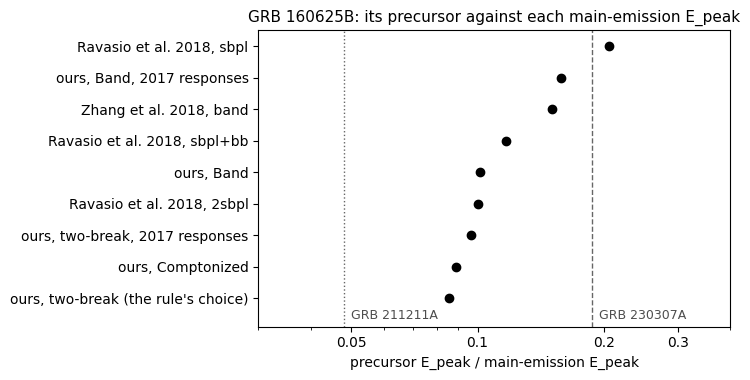

In [7]:
pe = mine.loc["PE", "Epeak"]
me = {"ours, two-break (the rule's choice)": mine.loc["ME", "Epeak_lowbreak"], "ours, Band": mine.loc["ME", "Epeak_band"],
      "ours, Comptonized": mine.loc["ME", "Epeak_cpl"], "ours, two-break, 2017 responses": old.loc["project_ME", "Epeak_lowbreak"],
      "ours, Band, 2017 responses": old.loc["project_ME", "Epeak_band"]}
for _, p in published[published.episode == "main"].iterrows():
    me[f"{p.source.replace('2018', ' et al. 2018').capitalize()}, {p.model}"] = p.Epeak_keV
r = pd.Series({k: pe / v for k, v in me.items()}).sort_values()
print(r.round(3).to_string())
print(f"at or above GRB 230307A's {SOFT}: {', '.join(r[r >= SOFT].index) or 'none'}; GRB 211211A's is 0.048")
fig, ax = plt.subplots(figsize=(7.5, 3.9))
ax.scatter(r.values, range(len(r)), color="k", zorder=3)
ax.set_yticks(range(len(r)), r.index)
for x, name, style in ((SOFT, "GRB 230307A", "--"), (0.048, "GRB 211211A", ":")):
    ax.axvline(x, color="0.4", ls=style, lw=1)
    ax.text(x * 1.04, -0.75, name, color="0.3", fontsize=9, va="bottom")
ax.set_xscale("log")
ax.set_xlim(0.03, 0.4)
ax.set_ylim(-0.9, len(r) - 0.5)
ax.xaxis.set_major_locator(FixedLocator([0.05, 0.1, 0.2, 0.3]))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("precursor E_peak / main-emission E_peak")
ax.set_title("GRB 160625B: its precursor against each main-emission E_peak", fontsize=11)
fig.tight_layout()
fig.savefig("figures/33_160625b_ratios.png", dpi=150)
plt.show()

Every main-emission E_peak from a model that describes the spectrum puts GRB 160625B's precursor below GRB 230307A's ratio. It's 0.085 to
0.16 with my fits on either version of the response files, 0.15 with Zhang et al.'s Band fit, and 0.10 with Ravasio et al.'s two-break
fit. Only Ravasio et al.'s smoothly broken power law, which they reject themselves (reduced chi-square 6.5), would put it above, at 0.21.
So notebook 29's finding stands: a precursor as soft against its main emission as a merger's, in a long burst that Zhang et al. place
with the collapsars. The version of the response files does matter for this burst's main emission (its E_peak as a whole is 13% higher
with the 2020 files with the two-break model, and 56% with Band), and section 3 asks how often that happens.

## 3 Our fits against the GBM catalogue's

The GBM catalogue fits every burst's brightest second (its peak-flux spectrum) with its own choice of detectors and channels. Repeating
exactly that fit with our set-up (`zhu.refit.catalogue_peak`: the batch's background and spectra, and a Comptonized model like the
catalogue's) checks the data handling burst by burst, across both samples. The catalogue's fits were made with the response files of
their day, and the archive has regenerated some since, so I split the comparison by whether the two sides used the same version.

206 bursts; fitted 196; not fitted: no peak-flux fit in the catalogue files 7; no response file here for n3 1; no response file here for nb 1; the interval is outside the TTE data (-131 to 62 s) 1
different responses: 52 bursts, ours / catalogue's E_peak median 1.001 (16-84%: 0.985 to 1.055), within 2 sigma 51
same responses: 144 bursts, ours / catalogue's E_peak median 1.000 (16-84%: 0.972 to 1.034), within 2 sigma 141
both E_peaks known to 30%: different responses 38 bursts, median 1.001; same responses 113 bursts, median 1.001
outside 2 sigma:
  burst our_responses   cat_Ep    my_Ep  ratio  sigma  cat_alpha  my_alpha  precursor                                                                                         background_flags
180728A           v02  270.834  132.109  0.488 -3.299     -1.900    -1.532       True                                                                                                         
120716A           v02  169.018  121.681  0.720 -2.511     -0.834 

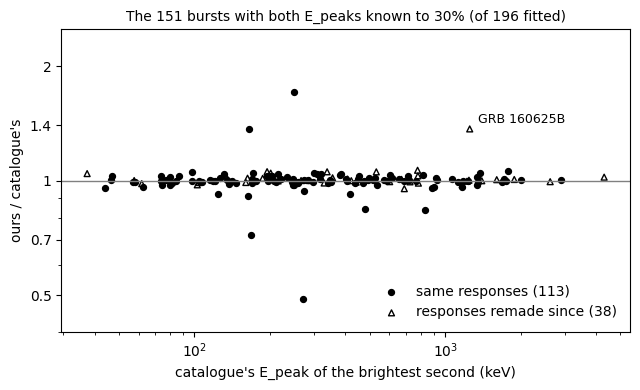

In [8]:
path = Path("results/catalogue_check/peak_seconds.csv")
if not path.exists():
    R.run_catalogue_peaks(workers=3)
peaks = pd.read_csv(path)
ok = peaks[peaks.my_Ep.notna() & peaks.cat_Ep.notna()].copy()
ok["ratio"] = ok.my_Ep / ok.cat_Ep
print(f"{len(peaks)} bursts; fitted {len(ok)}; not fitted: " + "; ".join(f"{k} {v}" for k, v in peaks.note.dropna().str.split(":").str[0].value_counts().items()))
for same, g in ok.groupby("same_responses"):
    lo, mid, hi = np.percentile(g.ratio, [16, 50, 84])
    print(f"{'same' if same else 'different'} responses: {len(g)} bursts, ours / catalogue's E_peak median {mid:.3f} (16-84%: {lo:.3f} to {hi:.3f}), "
          f"within 2 sigma {int((g.sigma.abs() < 2).sum())}")
known = ok[(ok.cat_Ep_err / ok.cat_Ep < 0.3) & (ok.my_Ep_err / ok.my_Ep < 0.3)]
print("both E_peaks known to 30%: " + "; ".join(f"{'same' if same else 'different'} responses {len(g)} bursts, median {g.ratio.median():.3f}"
                                           for same, g in known.groupby("same_responses")))
import json
outside = ok[ok.sigma.abs() >= 2].copy()
record = lambda b: json.loads(((ZHU / b) if (ZHU / b).is_dir() else (COPPIN / b)).joinpath("episodes.json").read_text())
outside["background_flags"] = [" ".join(record(b).get("bkg_flags", [])) for b in outside.burst]
outside["precursor"] = [record(b)["modes"]["zhu2026"].get("pe") is not None for b in outside.burst]
print("outside 2 sigma:")
print(outside[["burst", "our_responses", "cat_Ep", "my_Ep", "ratio", "sigma", "cat_alpha", "my_alpha", "precursor", "background_flags"]].round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(6.5, 4))
for same, marker, label in ((True, "o", "same responses"), (False, "^", "responses remade since")):
    g = known[known.same_responses == same]
    ax.scatter(g.cat_Ep, g.ratio, marker=marker, s=18, facecolors="k" if same else "none", edgecolors="k", label=f"{label} ({len(g)})")
b = known[known.burst == "160625B"]
for _, row in b.iterrows():
    ax.annotate("GRB 160625B", (row.cat_Ep, row.ratio), xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.axhline(1, color="0.5", lw=1)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(0.4, 2.5)
ax.yaxis.set_major_locator(FixedLocator([0.5, 0.7, 1, 1.4, 2]))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("catalogue's E_peak of the brightest second (keV)")
ax.set_ylabel("ours / catalogue's")
ax.set_title(f"The {len(known)} bursts with both E_peaks known to 30% (of {len(ok)} fitted)", fontsize=10)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig("figures/33_against_catalogue.png", dpi=150)
plt.show()

Where both sides used the same response files, my fit of the brightest second gives the GBM team's E_peak back. That's 144 bursts, with a
median ratio of 1.000 (16th to 84th percentiles 0.97 to 1.03) and 141 within two of the combined errors. Restricted to the 113 where both
E_peaks are known to 30%, it's 1.001. Of the three outside, two carry the batch's own warning that their background fit is poor (GRB
190205A, whose emission runs to the end of the TTE data, and GRB 120716A), and neither gives the samples an E_peak. The third, GRB 180728A
(3.3 sigma), has a Comptonized index of -1.90 in the catalogue's fit. That's close to -2, where E_peak and the index trade off. Where the
archive's response files have been made again since the catalogue's fit, the two still agree for 51 of 52 bursts (median 1.001), so a
new version usually changes little. GRB 160625B is the exception: 11 sigma apart with the 2020 files, and within 2 with the 2017 ones
(section 2). So the data handling is right, and a published E_peak should only be set against ours on the same response files.

## 4 The confirmed bursts, with the precursors that are only bounded

Notebook 26 compares the confirmed mergers' precursors with the supernova collapsars' through E_p,PE / E_p,ME, which it only works out
where our rule measures both E_peaks. Two of the five supernova collapsars it measures, GRB 180728A and 190114C, have precursors whose
E_peak our rule doesn't count as measured. A Comptonized spectrum doesn't fit them better than a power law, because their spectra fall
across the whole band (notebook 27 finds both soft in BAT as well). But the one-sided 95% limits on their E_peak (where the fit's C rises
by 2.71) still bound the ratio. So here every confirmed burst is set out, with its ratio where both E_peaks are measured and its range
where one is only bounded. The main emission's E_peak is our rule's, refitted where section 1 refitted it, and Zhu et al.'s own E_p,ME is
set next to it.

In [9]:
from zhu.laws import CONFIRMED

f = collect("zhu2026", ZHU)
table = pd.read_csv("shared/zhu2026_table1.csv", comment="#").set_index("GRB")
refit = (ran[ran.ours & (ran["sample"] == "zhu") & (ran.label == "ME") & ran.modes.str.contains("zhu2026")].set_index("burst")
         if len(ran) else pd.DataFrame(columns=["new_Epeak", "new_Epeak_err_lo", "new_Epeak_err_hi"]))
pre_230307A = pd.read_csv("shared/epeak_230307A.csv", comment="#").set_index("label").loc["pre"]      # notebook 12's precursor window


def dex(value, lo, hi):
    """The lower and upper errors of log10(value)."""
    return np.log10(value) - np.log10(max(value - lo, 1e-9)), np.log10(value + hi) - np.log10(value)


rows = []
for name, origin in CONFIRMED.items():
    if name not in f.index or pd.isna(f.Ep_ME_ours.get(name)):
        print(f"GRB {name} ({origin}): no main-emission E_peak of ours (notebook 23)")
        continue
    r = f.loc[name]
    if name in refit.index:
        me, me_lo, me_hi = refit.loc[name, ["new_Epeak", "new_Epeak_err_lo", "new_Epeak_err_hi"]].astype(float)
    else:
        me, me_lo, me_hi = float(r.Ep_ME_ours), float(r.Ep_ME_ours_lo), float(r.Ep_ME_ours_hi)
    row = dict(GRB=name, origin=origin, ME_measured=str(r.measured_ME) == "True", Ep_ME=me, Ep_ME_table=table.Ep_ME.get(name, np.nan))
    if pd.isna(r.get("sigma_PE")):
        pe, pe_lo, pe_hi, how, sigma = pre_230307A.Epeak_keV, pre_230307A.Epeak_err_lo, pre_230307A.Epeak_err_hi, "notebook 12", np.nan
    else:
        pe, pe_lo, pe_hi, sigma = float(r.Ep_PE_ours), float(r.Ep_PE_ours_lo), float(r.Ep_PE_ours_hi), float(r.sigma_PE)
        how = "measured" if str(r.measured_PE) == "True" else "bounded"
    row.update(PE=how, sigma_PE=sigma, Ep_PE=pe, ratio=pe / me, ratio_table=pe / row["Ep_ME_table"])
    if how == "bounded":
        lo, hi = float(r.Ep_PE_cpl_limit_lo), float(r.Ep_PE_cpl_limit_hi)
        pl = pd.read_csv(ZHU / name / "spectra_zhu2026.csv").set_index("label").loc["PE", "pl_index"]
        row.update(Ep_PE_low=lo, Ep_PE_high=hi, ratio_low=lo / me, ratio_high=hi / me, ratio_table_low=lo / row["Ep_ME_table"],
                   ratio_table_high=hi / row["Ep_ME_table"], PE_power_law_index=pl)
    elif row["ME_measured"]:
        a = dex(pe, pe_lo, pe_hi)
        b = tuple(x if np.isfinite(x) else 0.0 for x in dex(me, me_lo, me_hi))      # GRB 090618's E_p,ME has no error: its search failed
        row.update(ratio_low=pe / me / 10 ** np.hypot(a[0], b[1]), ratio_high=pe / me * 10 ** np.hypot(a[1], b[0]),
                   ME_error=bool(np.isfinite(me_lo) and np.isfinite(me_hi)))
    rows.append(row)
confirmed = pd.DataFrame(rows).set_index("GRB")
print(confirmed.round(3).to_string())
print(f"GRB 230307A's ratio (the line of the soft list): {SOFT}")

GRB 111228A (collapsar): no main-emission E_peak of ours (notebook 23)
            origin  ME_measured     Ep_ME  Ep_ME_table           PE  sigma_PE    Ep_PE  ratio  ratio_table  ratio_low  ratio_high ME_error  Ep_PE_low  Ep_PE_high  ratio_table_low  ratio_table_high  PE_power_law_index
GRB                                                                                                                                                                                                                     
211211A     merger         True  1364.770      1176.99     measured    23.070   65.945  0.048        0.056      0.044       0.053     True        NaN         NaN              NaN               NaN                 NaN
230307A     merger         True   907.672       962.46  notebook 12       NaN  170.300  0.188        0.177      0.182       0.194     True        NaN         NaN              NaN               NaN                 NaN
090618A  collapsar         True   241.186       170.16     me

Notebook 26's estimate of how many confirmed mergers a test would need took the collapsars' log ratio from the two that are measured.
Here it is again with the two bounded collapsars counted, once at their best fits and once at the hard ends of their bounds, which is the
hardest they can be and leaves the mergers the widest gap. The assumptions are notebook 26's: the mergers' mean from GRB 211211A and
230307A, the candidates' scatter (0.44 dex), ten collapsars, and Welch's test at 5%, one-sided.

In [10]:
from scipy.stats import ttest_ind
log_kn = np.log10(confirmed.loc[confirmed.origin == "merger", "ratio"])
sn = confirmed[(confirmed.origin == "collapsar") & confirmed.ME_measured]
cases = {"measured only (notebook 26)": np.log10(sn.loc[sn.PE == "measured", "ratio"]),
         "with the bounded at their best fits": np.log10(sn.ratio),
         "with the bounded at their hard ends": np.log10(sn.ratio_high.where(sn.PE == "bounded", sn.ratio))}
scatter = 0.44
rng = np.random.default_rng(7)
rows = []
for case, values in cases.items():
    row = {"collapsars": case, "n": len(values), "mean log ratio": round(values.mean(), 2), "gap to the mergers (dex)": round(values.mean() - log_kn.mean(), 2)}
    for n in (4, 8, 15, 30):
        row[f"power, {n} mergers"] = np.mean([ttest_ind(rng.normal(log_kn.mean(), scatter, n), rng.normal(values.mean(), scatter, 10),
                                                        equal_var=False, alternative="less").pvalue < 0.05 for _ in range(2000)])
    rows.append(row)
print(f"confirmed mergers: mean log ratio {log_kn.mean():.2f} ({len(log_kn)})")
print(pd.DataFrame(rows).set_index("collapsars").round(2).to_string())

confirmed mergers: mean log ratio -1.02 (2)
                                     n  mean log ratio  gap to the mergers (dex)  power, 4 mergers  power, 8 mergers  power, 15 mergers  power, 30 mergers
collapsars                                                                                                                                                
measured only (notebook 26)          2           -0.05                      0.97              0.93              1.00               1.00               1.00
with the bounded at their best fits  4           -0.74                      0.28              0.24              0.35               0.45               0.49
with the bounded at their hard ends  4           -0.54                      0.48              0.49              0.70               0.82               0.90


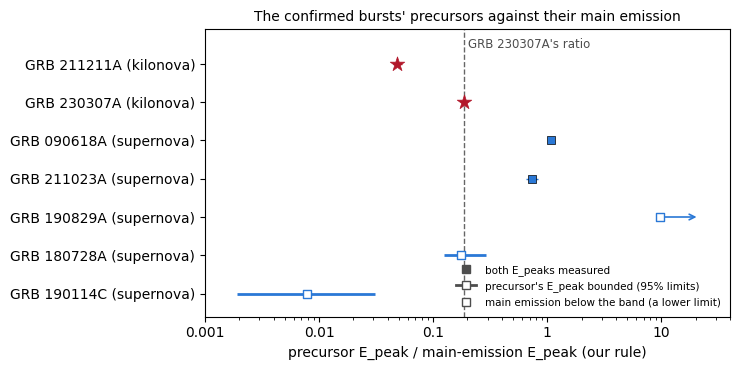

In [11]:
from matplotlib.lines import Line2D
order = ["211211A", "230307A", "090618A", "211023A", "190829A", "180728A", "190114C"]
c = confirmed.reindex([n for n in order if n in confirmed.index])
colour = {"merger": "#b2182b", "collapsar": "#2a78d6"}
marker = {"merger": "*", "collapsar": "s"}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for y, (name, r) in enumerate(c.iterrows()):
    col, m = colour[r.origin], marker[r.origin]
    size = 120 if m == "*" else 40
    if r.PE == "bounded":
        ax.plot([r.ratio_low, r.ratio_high], [y, y], color=col, lw=2.0, solid_capstyle="butt")
        ax.scatter([r.ratio], [y], marker=m, s=size, facecolors="white", edgecolors=col, linewidths=1.0, zorder=3)
    elif not r.ME_measured:          # the main emission peaks below the band: the ratio is a lower limit
        ax.annotate("", xy=(r.ratio * 2.2, y), xytext=(r.ratio, y), arrowprops=dict(arrowstyle="->", color=col, lw=1.2))
        ax.scatter([r.ratio], [y], marker=m, s=size, facecolors="white", edgecolors=col, linewidths=1.0, zorder=3)
    else:
        ax.errorbar([r.ratio], [y], xerr=[[r.ratio - r.ratio_low], [r.ratio_high - r.ratio]], fmt="none", ecolor=col, lw=1.0, capsize=0)
        ax.scatter([r.ratio], [y], marker=m, s=size, color=col, edgecolors="k" if m == "s" else col, linewidths=0.5, zorder=3)
ax.axvline(SOFT, color="0.4", ls="--", lw=1)
ax.text(SOFT * 1.08, -0.5, "GRB 230307A's ratio", color="0.3", fontsize=8.5, va="center")
labels = [f"GRB {n} ({'kilonova' if r.origin == 'merger' else 'supernova'})" for n, r in c.iterrows()]
ax.set_yticks(range(len(c)), labels)
ax.set_ylim(len(c) - 0.4, -0.9)
ax.set_xscale("log")
ax.set_xlim(1e-3, 40)
ax.xaxis.set_major_locator(FixedLocator([0.001, 0.01, 0.1, 1, 10]))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("precursor E_peak / main-emission E_peak (our rule)")
key = [Line2D([], [], color="0.3", marker="s", ls="none", label="both E_peaks measured"),
       Line2D([], [], color="0.3", marker="s", markerfacecolor="white", lw=2, label="precursor's E_peak bounded (95% limits)"),
       Line2D([], [], color="0.3", marker="s", markerfacecolor="white", ls="none", label="main emission below the band (a lower limit)")]
ax.legend(handles=key, fontsize=7.5, loc="lower right", frameon=False)
ax.set_title("The confirmed bursts' precursors against their main emission", fontsize=10)
fig.tight_layout()
fig.savefig("figures/33_confirmed_ratios.png", dpi=150)
plt.show()

Of the five supernova collapsars with a main-emission E_peak of ours, the two whose ratio is measured are about as hard as their main
emission (GRB 211023A 0.73, GRB 090618 1.08). GRB 190829A goes the other way (9.8 or more, with its main emission peaking below GBM's
band). The other two are as soft as the mergers:
- GRB 180728A's precursor, at 22.6 sigma, peaks at 13 keV (95% limits 9.4 and 21.7 keV), against 75 keV for its main emission. That's a
  ratio between 0.13 and 0.29, around GRB 230307A's 0.19 (0.09 to 0.22 with Zhu et al.'s E_p,ME of 99 keV). Fitted their way after
  section 1's refit, this precursor prefers a Comptonized model plus a blackbody, with the Comptonized part peaking at 71 keV. But the
  spectrum as a whole still falls across the band: a power law of index -2.25 here, and -2.56 in BAT (notebook 27).
- GRB 190114C's precursor is below 20 keV against 653 keV, a ratio below 0.031, softer even than GRB 211211A's 0.048. It's faint, though
  (4.7 sigma, under the 5 our rule asks of a usable spectrum), so it counts for less.

Counting these two changes notebook 26's planning estimate:
- From the two measured collapsars alone, their mean log ratio is -0.05, 0.97 dex above the mergers' -1.02, and four confirmed mergers
  against ten collapsars would give a 90% chance of a 5% result.
- With the two bounded ones at their best fits, the gap is 0.28 dex, and the chance stays below 50% even with 30 mergers.
- At the hard ends of their bounds, the gap is 0.48 dex, and it takes about 30 mergers.

What's measured: among the bursts whose origin is known, a soft precursor isn't the mergers' alone. The soft end holds both confirmed
mergers and two of the five supernova collapsars. So softness against the main emission, which notebook 26 found adds nothing to EPI,
doesn't single out the confirmed mergers either, as GRB 160625B (section 2) had already suggested in Coppin et al.'s sample. If it
separates them at all, it would take tens of confirmed mergers to show it, not four.